# Упражнения по регуляризации и методу градиентного спуска

## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\\text{true}} = 2.5 \\cdot \\sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\\sigma(x) = 0.15 \\cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

Train: (175, 1), Test: (75, 1)
sigma(x): от 0.154 до 0.745
Неустранимая ошибка: sqrt(mean(sigma^2)) = 0.479


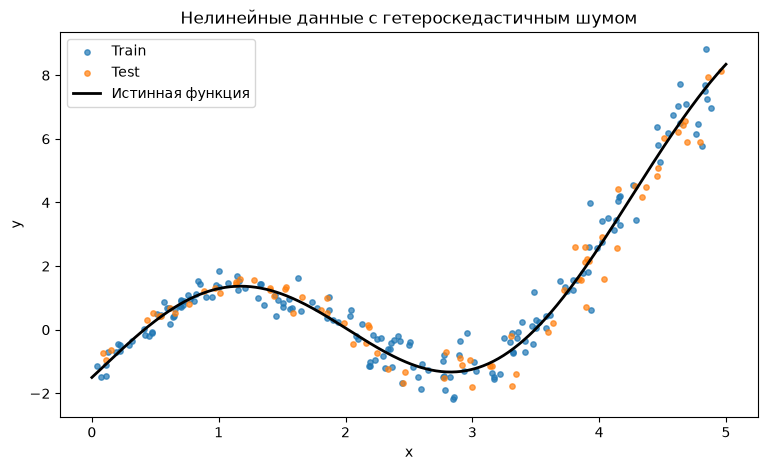

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.linear_model import (
    ElasticNet,
    LassoCV,
    LinearRegression,
    Ridge,
    RidgeCV,
    SGDRegressor,
    lasso_path,
)
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, learning_curve, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

rng = np.random.default_rng(42)


def true_function(x):
    return 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5


x = rng.uniform(0, 5, 250)
sigma = 0.15 * (1 + 0.8 * x)
y = true_function(x) + rng.normal(0, sigma)

X_train, X_test, y_train, y_test = train_test_split(x.reshape(-1, 1), y, test_size=0.3, random_state=42)
x_grid = np.linspace(0, 5, 500).reshape(-1, 1)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"sigma(x): от {sigma.min():.3f} до {sigma.max():.3f}")
print(f"Неустранимая ошибка: sqrt(mean(sigma^2)) = {np.sqrt(np.mean(sigma**2)):.3f}")

plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, s=15, alpha=0.7, label="Train")
plt.scatter(X_test, y_test, s=15, alpha=0.7, label="Test")
plt.plot(x_grid, true_function(x_grid), color="black", lw=2, label="Истинная функция")
plt.title("Нелинейные данные с гетероскедастичным шумом")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

Вывод: Я сгенерировал 250 точек x как случайную выборку из равномерного распределения на отрезке [0, 5] и разделил их на 175 обучающих и 75 тестовых (random_state=42). В условии сказано, что линейно растёт дисперсия, но формула задаёт стандартное отклонение σ(x), поэтому я генерировал шум строго по формуле, и σ меняется от 0.154 до 0.745. На графике видно, что справа точки разбросаны вокруг истинной функции заметно сильнее, потому что шум растёт с x. Неустранимая ошибка sqrt(mean(σ²)) получилась 0.479, то есть даже идеальная модель будет иметь RMSE около 0.48, и с этим числом я сравниваю модели в заданиях 2 и 3.

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

RMSE train: 0.4601
RMSE test:  0.6319
RMSE test без точек правее последней обучающей (1 шт.): 0.5186
Ранг матрицы признаков в МНК: 11 из 25
Диапазон x в train: [0.037, 4.878]
Предсказания на [0, 5]: от -1.36 до 14.92
Истинная функция на [0, 5]: от -1.50 до 8.34


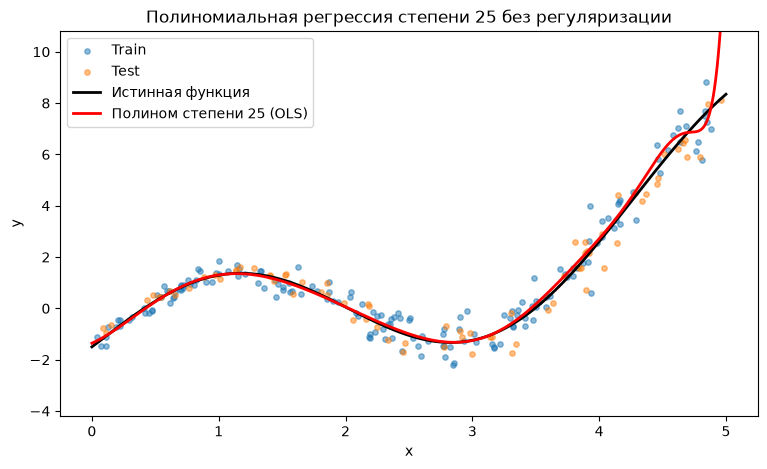

In [2]:
poly25 = make_pipeline(PolynomialFeatures(degree=25, include_bias=False), StandardScaler(), LinearRegression())
poly25.fit(X_train, y_train)

print(f"RMSE train: {root_mean_squared_error(y_train, poly25.predict(X_train)):.4f}")
print(f"RMSE test:  {root_mean_squared_error(y_test, poly25.predict(X_test)):.4f}")
inside_train_range = X_test.ravel() <= X_train.max()
print(f"RMSE test без точек правее последней обучающей ({(~inside_train_range).sum()} шт.): "
      f"{root_mean_squared_error(y_test[inside_train_range], poly25.predict(X_test[inside_train_range])):.4f}")
print(f"Ранг матрицы признаков в МНК: {poly25[-1].rank_} из 25")

y_grid_pred = poly25.predict(x_grid)
print(f"Диапазон x в train: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Предсказания на [0, 5]: от {y_grid_pred.min():.2f} до {y_grid_pred.max():.2f}")
print(f"Истинная функция на [0, 5]: от {true_function(x_grid).min():.2f} до {true_function(x_grid).max():.2f}")

plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, s=15, alpha=0.5, label="Train")
plt.scatter(X_test, y_test, s=15, alpha=0.5, label="Test")
plt.plot(x_grid, true_function(x_grid), color="black", lw=2, label="Истинная функция")
plt.plot(x_grid, y_grid_pred, color="red", lw=2, label="Полином степени 25 (OLS)")
plt.ylim(y.min() - 2, y.max() + 2)
plt.title("Полиномиальная регрессия степени 25 без регуляризации")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

Вывод: Полином 25-й степени без регуляризации дал RMSE 0.460 на обучающей выборке и 0.632 на тестовой. Ошибка на обучении ниже неустранимой 0.479 (задание 1), значит, модель подстроилась под шум, а на новых данных ошибается сильнее, то есть переобучилась. Сильнее всего это видно у правого края: обучающие точки заканчиваются на x = 4.878, после этого предсказание уходит вверх до 14.92, хотя истинная функция не больше 8.34, а перед этим кривая колеблется между точками. Это эффект Рунге: у полинома высокой степени старшие степени x сильнее всего влияют на краях отрезка, где точек мало и шум самый большой. Одна тестовая точка лежит правее последней обучающей, и без неё RMSE на тесте 0.519, поэтому заметная часть тестовой ошибки приходится на этот край. Перед регрессией я добавил StandardScaler, потому что x в 25-й степени достигает порядка 10^17 и без масштабирования МНК считается неточно, но ранг матрицы признаков всё равно получился только 11 из 25, так как высокие степени x почти линейно зависимы.

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.\

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей."

LinearRegression, степень 15 | Train: RMSE при n=14 = 0.1707, при n=140 = 0.4589
LinearRegression, степень 15 | Validation: RMSE при n=14 = 4380.7691, при n=140 = 0.4943


Ridge (alpha=1.0), степень 15 | Train: RMSE при n=14 = 0.7414, при n=140 = 0.7298
Ridge (alpha=1.0), степень 15 | Validation: RMSE при n=14 = 6.3587, при n=140 = 0.7416


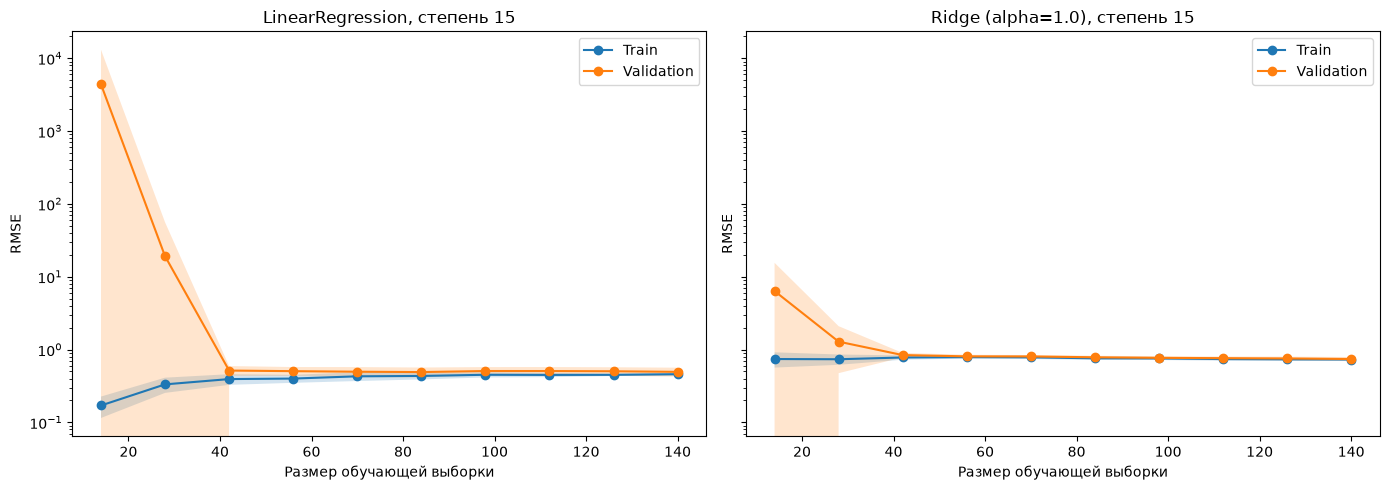

In [3]:
def plot_learning_curve(model, X, y, title, ax):
    sizes, train_scores, val_scores = learning_curve(
        model,
        X,
        y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5,
        scoring="neg_root_mean_squared_error",
        shuffle=True,
        random_state=42,
    )
    for scores, label in [(-train_scores, "Train"), (-val_scores, "Validation")]:
        mean, std = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(sizes, mean, "o-", label=label)
        ax.fill_between(sizes, mean - std, mean + std, alpha=0.2)
        print(f"{title} | {label}: RMSE при n={sizes[0]} = {mean[0]:.4f}, при n={sizes[-1]} = {mean[-1]:.4f}")
    ax.set(title=title, xlabel="Размер обучающей выборки", ylabel="RMSE", yscale="log")
    ax.legend()


lin15 = make_pipeline(PolynomialFeatures(degree=15, include_bias=False), StandardScaler(), LinearRegression())
ridge15 = make_pipeline(PolynomialFeatures(degree=15, include_bias=False), StandardScaler(), Ridge(alpha=1.0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_learning_curve(lin15, X_train, y_train, "LinearRegression, степень 15", axes[0])
plot_learning_curve(ridge15, X_train, y_train, "Ridge (alpha=1.0), степень 15", axes[1])
plt.tight_layout()
plt.show()

Вывод: Я написал функцию plot_learning_curve, которая через learning_curve считает RMSE на 5-кратной кросс-валидации только по обучающей выборке, и построил кривые для полиномов 15-й степени. У LinearRegression при n = 14 RMSE на обучении 0.1707, а на валидации около 4381, потому что модель с 15 коэффициентами почти проходит через все точки и сильно колеблется между ними, то есть у неё большая дисперсия. С ростом выборки разрыв быстро уменьшается, и при n = 140 RMSE 0.4589 на обучении и 0.4943 на валидации, что уже близко к неустранимой ошибке 0.479 (задание 1). У Ridge с alpha = 1 при n = 14 валидационная ошибка 6.3587, то есть намного меньше, чем у LinearRegression, а при n = 140 разрыв почти исчез (0.7298 и 0.7416), потому что штраф L2 не даёт коэффициентам становиться большими. Но обе ошибки Ridge выше 0.479 и выше, чем у LinearRegression, поэтому, скорее всего, alpha = 1 здесь слишком большое и модель недообучена. Кривые Ridge уже вышли на плато, поэтому новые данные ей почти не помогут, и alpha лучше подбирать на кросс-валидации.

## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.\

Разделите данные на обучающую и тестовую выборки (70/30).

In [4]:
ames = pd.read_csv("Ames_Housing_Sales.csv")
print(f"Размер датасета: {ames.shape}, дубликатов: {ames.duplicated().sum()}")

ames["MSSubClass"] = ames["MSSubClass"].astype(str)
cat_cols = ames.select_dtypes(exclude="number").columns
num_cols = ames.select_dtypes(include="number").columns.drop("SalePrice")
print(f"Пропуски только в категориальных признаках: {ames[num_cols].isna().sum().sum() == 0}")
ames[cat_cols] = ames[cat_cols].fillna("None")
print(f"Категориальных признаков: {len(cat_cols)}, числовых: {len(num_cols)}")
print(f"Асимметрия SalePrice: {ames['SalePrice'].skew():.2f}")

X_ames = pd.get_dummies(ames.drop(columns="SalePrice"), columns=cat_cols, drop_first=True, dtype=float)
y_ames = np.log1p(ames["SalePrice"])

X_train_ames, X_test_ames, y_train_ames, y_test_ames = train_test_split(X_ames, y_ames, test_size=0.3, random_state=42)

train_skew = X_train_ames[num_cols].skew()
skewed_cols = train_skew[train_skew > 0.75].index
print(f"Признаков со skew > 0.75: {len(skewed_cols)}")
print(train_skew[skewed_cols].sort_values(ascending=False).round(2).to_string())
X_train_ames[skewed_cols] = np.log1p(X_train_ames[skewed_cols])
X_test_ames[skewed_cols] = np.log1p(X_test_ames[skewed_cols])

key_cols = ["LotArea", "GrLivArea", "TotalBsmtSF"]
interactions = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False).set_output(transform="pandas")
X_train_ames = X_train_ames.join(interactions.fit_transform(X_train_ames[key_cols]).drop(columns=key_cols))
X_test_ames = X_test_ames.join(interactions.transform(X_test_ames[key_cols]).drop(columns=key_cols))

print(f"Добавленные взаимодействия: {list(X_train_ames.columns[-3:])}")
print(f"X_train_ames: {X_train_ames.shape}, X_test_ames: {X_test_ames.shape}")

Размер датасета: (1379, 80), дубликатов: 0
Пропуски только в категориальных признаках: True
Категориальных признаков: 44, числовых: 35
Асимметрия SalePrice: 1.94
Признаков со skew > 0.75: 22
MiscVal          26.92
PoolArea         15.78
LotArea          11.50
LowQualFinSF     11.21
3SsnPorch        10.15
KitchenAbvGr      5.50
ScreenPorch       4.60
BsmtFinSF2        4.47
BsmtHalfBath      3.88
EnclosedPorch     3.22
LotFrontage       3.14
MasVnrArea        2.49
OpenPorchSF       2.30
BsmtFinSF1        2.01
TotalBsmtSF       1.98
1stFlrSF          1.54
GrLivArea         1.46
WoodDeckSF        1.33
OverallCond       0.99
BsmtUnfSF         0.90
GarageArea        0.84
2ndFlrSF          0.77
Добавленные взаимодействия: ['LotArea GrLivArea', 'LotArea TotalBsmtSF', 'GrLivArea TotalBsmtSF']
X_train_ames: (965, 267), X_test_ames: (414, 267)


Вывод: В датасете 1379 объектов и 80 столбцов, дубликатов нет, а пропуски есть только в категориальных признаках, потому что строку None (нет подвала, бассейна и т. п.) pandas читает как пропуск, поэтому я вернул её как отдельную категорию. Признак MSSubClass я тоже отнёс к категориальным, так как это код типа дома, и закодировал 44 категориальных признака через One-Hot Encoding с drop_first=True. Разбиение 70/30 (random_state=42) я сделал до проверки асимметрии, чтобы решение о логарифмировании принималось только по обучающей выборке и не было утечки данных, и skew > 0.75 оказался у 22 из 35 числовых признаков, включая LotArea, GrLivArea и TotalBsmtSF. Целевую переменную SalePrice я тоже прологарифмировал, потому что её skew равен 1.94, поэтому все RMSE в заданиях 5–8 считаются в логарифмах цены и примерно означают относительную ошибку. После добавления трёх попарных взаимодействий ключевых признаков получилось 267 признаков, 965 объектов в обучающей и 414 в тестовой выборке. Ограничение в том, что взаимодействия построены по уже прологарифмированным признакам, как в порядке шагов условия, поэтому их сложнее интерпретировать.

## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке."

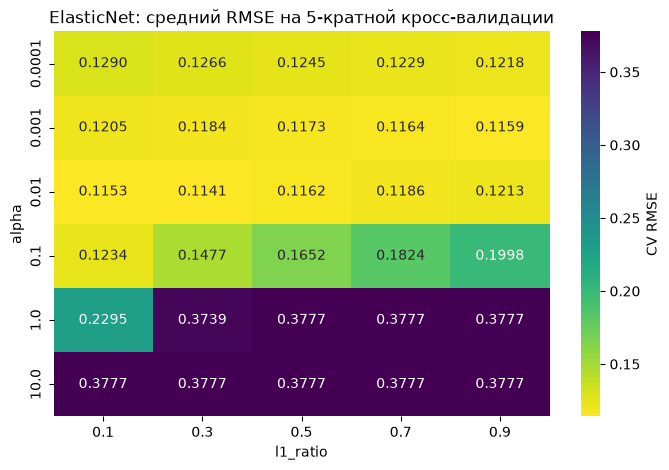

Оптимальные параметры: {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.3}
CV RMSE: 0.1141
Test RMSE: 0.1790
Три наибольшие |ошибки| на test: [1.766, 1.551, 1.201]
Test RMSE без двух худших объектов: 0.1371


In [5]:
param_grid = {
    "elasticnet__alpha": [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
    "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
}
elastic_search = GridSearchCV(
    make_pipeline(StandardScaler(), ElasticNet(max_iter=50000)),
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
elastic_search.fit(X_train_ames, y_train_ames)

cv_rmse = pd.DataFrame(elastic_search.cv_results_["params"]).assign(rmse=-elastic_search.cv_results_["mean_test_score"])
heatmap_data = cv_rmse.pivot(index="elasticnet__alpha", columns="elasticnet__l1_ratio", values="rmse")

plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap="viridis_r", cbar_kws={"label": "CV RMSE"})
plt.title("ElasticNet: средний RMSE на 5-кратной кросс-валидации")
plt.xlabel("l1_ratio")
plt.ylabel("alpha")
plt.show()

elastic_test_errors = y_test_ames - elastic_search.predict(X_test_ames)
largest_errors = elastic_test_errors.abs().sort_values(ascending=False)
print(f"Оптимальные параметры: {elastic_search.best_params_}")
print(f"CV RMSE: {-elastic_search.best_score_:.4f}")
print(f"Test RMSE: {np.sqrt((elastic_test_errors ** 2).mean()):.4f}")
print(f"Три наибольшие |ошибки| на test: {largest_errors.head(3).round(3).tolist()}")
print(f"Test RMSE без двух худших объектов: {np.sqrt((largest_errors.iloc[2:] ** 2).mean()):.4f}")

Вывод: Лучшие параметры ElasticNet на 5-кратной кросс-валидации — alpha = 0.01 и l1_ratio = 0.3, CV RMSE 0.1141, а на тестовой выборке RMSE 0.1790. По тепловой карте при alpha = 0.0001 ошибка выше (0.1218–0.1290), потому что регуляризация слабая и модель переобучается, а начиная с alpha = 0.1 ошибка быстро растёт, и тем быстрее, чем больше l1_ratio, так как L1-штраф обнуляет всё больше коэффициентов. Почти везде при alpha ≥ 1 RMSE равен 0.3777, вероятно, потому что все коэффициенты обнулились и модель предсказывает просто среднее, исключение — alpha = 1 при l1_ratio = 0.1 (0.2295). StandardScaler я поставил внутрь Pipeline, поэтому в каждом фолде масштабирование обучается только на обучающей части. Тестовая ошибка заметно больше CV из-за нескольких объектов: две самые большие ошибки равны 1.766 и 1.551 в логарифмах, то есть цена для них занижена в несколько раз, и без них RMSE на тесте 0.1371. Итоговой оценкой я всё равно считаю 0.1790, потому что объекты из теста убирать нельзя, а параметры подбирались только по кросс-валидации.

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\\alpha$.
* Какая доля признаков была полностью исключена из модели?

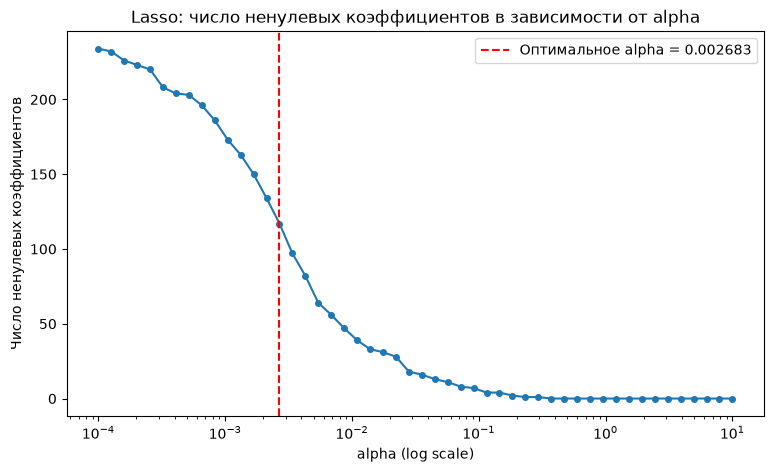

Оптимальное alpha: 0.002683
ТОП-10 признаков по |коэффициенту| (стандартизованные признаки):
GrLivArea                0.0879
OverallQual              0.0804
LotArea GrLivArea        0.0619
YearBuilt                0.0554
PoolQC_Gd               -0.0475
OverallCond              0.0416
BsmtFinSF1               0.0295
1stFlrSF                 0.0271
SaleCondition_Partial    0.0258
GarageCars               0.0238

Исключено признаков: 150 из 267 (56.2%)
Test RMSE LassoCV: 0.1808


In [6]:
alphas = np.logspace(-4, 1, 50)
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=50000, n_jobs=-1))
lasso.fit(X_train_ames, y_train_ames)
lasso_cv = lasso[-1]

X_train_std = lasso[0].transform(X_train_ames)
path_alphas, path_coefs, _ = lasso_path(X_train_std, y_train_ames - y_train_ames.mean(), alphas=alphas, max_iter=50000)
n_nonzero = (path_coefs != 0).sum(axis=0)

plt.figure(figsize=(9, 5))
plt.semilogx(path_alphas, n_nonzero, "o-", ms=4)
plt.axvline(lasso_cv.alpha_, color="red", ls="--", label=f"Оптимальное alpha = {lasso_cv.alpha_:.4g}")
plt.title("Lasso: число ненулевых коэффициентов в зависимости от alpha")
plt.xlabel("alpha (log scale)")
plt.ylabel("Число ненулевых коэффициентов")
plt.legend()
plt.show()

print(f"Оптимальное alpha: {lasso_cv.alpha_:.6f}")
lasso_coefs = pd.Series(lasso_cv.coef_, index=X_train_ames.columns)
top10 = lasso_coefs.loc[lasso_coefs.abs().sort_values(ascending=False).index[:10]]
print("ТОП-10 признаков по |коэффициенту| (стандартизованные признаки):")
print(top10.round(4).to_string())

n_zero = (lasso_coefs == 0).sum()
print(f"\nИсключено признаков: {n_zero} из {lasso_coefs.size} ({n_zero / lasso_coefs.size:.1%})")
print(f"Test RMSE LassoCV: {root_mean_squared_error(y_test_ames, lasso.predict(X_test_ames)):.4f}")

Вывод: LassoCV на 5-кратной кросс-валидации выбрал alpha ≈ 0.002683. На графике число ненулевых коэффициентов уменьшается с ростом alpha и при больших alpha доходит до нуля, потому что L1-штраф не просто уменьшает веса, а делает их ровно нулевыми. Самые важные признаки — GrLivArea (0.0879), OverallQual (0.0804) и взаимодействие LotArea GrLivArea (0.0619), дальше идут YearBuilt, OverallCond, BsmtFinSF1 и другие, и это логично, так как цена в основном зависит от площади, качества и возраста дома. Отрицательный коэффициент PoolQC_Gd (−0.0475), скорее всего, вызван единичными объектами с этой категорией, поэтому его интерпретировать ненадёжно. Из модели исключено 150 признаков из 267, то есть 56.2%, а RMSE на тесте 0.1808 почти такой же, как у ElasticNet (0.1790, задание 5), поэтому меньше половины признаков хватает для того же качества. Ограничение в том, что StandardScaler обучается на всей обучающей выборке до внутренней кросс-валидации LassoCV, поэтому выбор alpha немного видит статистики валидационных фолдов.

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

In [7]:
scaler = StandardScaler().fit(X_train_ames)
X_train_scaled = scaler.transform(X_train_ames)
X_test_scaled = scaler.transform(X_test_ames)

lr_schedules = {
    "constant": {"learning_rate": "constant", "eta0": 0.01},
    "optimal": {"learning_rate": "optimal"},
    "invscaling": {"learning_rate": "invscaling", "eta0": 0.01, "power_t": 0.25},
    "adaptive": {"learning_rate": "adaptive", "eta0": 0.01},
}


def sgd_report(schedules):
    rows = []
    for name, params in schedules.items():
        sgd = SGDRegressor(penalty="elasticnet", random_state=42, **params).fit(X_train_scaled, y_train_ames)
        rows.append({
            "learning_rate": name,
            "eta0": params.get("eta0", "—"),
            "RMSE train": root_mean_squared_error(y_train_ames, sgd.predict(X_train_scaled)),
            "RMSE test": root_mean_squared_error(y_test_ames, sgd.predict(X_test_scaled)),
            "n_iter_": sgd.n_iter_,
        })
    return pd.DataFrame(rows).set_index("learning_rate")


sgd_report(lr_schedules)

,eta0,RMSE train,RMSE test,n_iter_
learning_rate,,,,
constant,0.01,1.730692e+12,2.015009e+12,6
optimal,—,1.760948e+13,2.311299e+13,106
invscaling,0.01,5.290839e+01,2.081862e+01,6
adaptive,0.01,5.658236e+10,1.833154e+11,36


In [8]:
row_sq_norms = (X_train_scaled**2).sum(axis=1)
print(f"Число признаков: {X_train_scaled.shape[1]}")
print(f"||x||^2 строк: среднее = {row_sq_norms.mean():.0f}, медиана = {np.median(row_sq_norms):.0f}, максимум = {row_sq_norms.max():.0f}")
print(f"Граница устойчивости для среднего объекта: eta < 2 / mean(||x||^2) = {2 / row_sq_norms.mean():.4f}")

sgd_report({name: {**params, "eta0": 0.001} for name, params in lr_schedules.items() if "eta0" in params})

Число признаков: 267
||x||^2 строк: среднее = 257, медиана = 177, максимум = 2254
Граница устойчивости для среднего объекта: eta < 2 / mean(||x||^2) = 0.0078


,eta0,RMSE train,RMSE test,n_iter_
learning_rate,,,,
constant,0.001,1.384228,0.508982,10
invscaling,0.001,0.117652,0.206047,59
adaptive,0.001,0.081928,0.201385,42


Вывод: Я отмасштабировал признаки StandardScaler, обученным только на обучающей выборке, и при параметрах из условия все четыре версии SGDRegressor разошлись: RMSE на тесте от 20.8 у invscaling до 2.3e+13 у optimal, а маленькие n_iter_ (от 6 до 106) означают не сходимость, а остановку, потому что ошибка перестала уменьшаться. Причина в масштабе данных: шаг SGD устойчив, только если eta·‖x‖² < 2, а у меня в среднем ‖x‖² = 257 (максимум 2254), поэтому граница устойчивости около 0.0078, и eta0 = 0.01 больше неё. Схема optimal не использует eta0, её шаг зависит от alpha, и при alpha = 0.0001 он, скорее всего, в начале ещё больше. Поэтому я повторил остальные схемы с eta0 = 0.001: adaptive дала RMSE на тесте 0.2014 за 42 эпохи, invscaling — 0.2060 за 59, а constant осталась нестабильной (0.5090), так как её шаг не уменьшается, а для объектов с большой нормой он всё равно слишком большой. Adaptive оказалась лучше, потому что держит шаг, пока ошибка падает, и уменьшает его в 5 раз, когда она перестаёт уменьшаться. Даже лучший SGD хуже ElasticNet и Lasso (0.1790 и 0.1808, задания 5 и 6), а RMSE 0.0819 на обучении против 0.2014 на тесте показывает переобучение при слабом штрафе alpha = 0.0001.

## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

Сделайте выводы об устойчивости функции потерь Хьюбера по сравнению с классической регрессией.

     

In [9]:
outlier_rng = np.random.default_rng(42)
outlier_idx = outlier_rng.choice(len(y_train_ames), size=round(0.05 * len(y_train_ames)), replace=False)
y_train_outliers = y_train_ames.copy()
y_train_outliers.iloc[outlier_idx] = np.log1p(3 * np.expm1(y_train_outliers.iloc[outlier_idx]))
print(f"Искажено точек: {len(outlier_idx)} из {len(y_train_ames)}")

robust_models = {
    "OLS": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=np.logspace(-2, 4, 50)),
    "SGD squared_error": SGDRegressor(loss="squared_error", learning_rate="adaptive", eta0=0.001, random_state=42),
    "SGD huber": SGDRegressor(loss="huber", learning_rate="adaptive", eta0=0.001, random_state=42),
}
robust_rows = []
for name, model in robust_models.items():
    for train_target, y_fit in [("чистые", y_train_ames), ("с выбросами", y_train_outliers)]:
        y_pred = clone(model).fit(X_train_scaled, y_fit).predict(X_test_scaled)
        robust_rows.append({
            "Модель": name,
            "Train y": train_target,
            "RMSE": root_mean_squared_error(y_test_ames, y_pred),
            "MAE": mean_absolute_error(y_test_ames, y_pred),
        })
pd.DataFrame(robust_rows).pivot(index="Модель", columns="Train y", values=["RMSE", "MAE"]).loc[list(robust_models)]

Искажено точек: 48 из 965


RMSE                   MAE          
Train y           с выбросами    чистые с выбросами    чистые
Модель                                                       
OLS                  0.251941  0.168748    0.165787  0.101646
RidgeCV              0.177020  0.172465    0.117890  0.096583
SGD squared_error    0.256597  0.201552    0.157362  0.113468
SGD huber            0.190288  0.183098    0.099454  0.097292

Вывод: Я случайно выбрал 48 из 965 объектов обучающей выборки (5%) и утроил для них цену, а так как целевая переменная в логарифмах, в лог-шкале это примерно +1.1. Каждую модель я обучил на чистых и на искажённых y и сравнил ошибки на одной и той же чистой тестовой выборке. Сильнее всего ухудшились OLS (MAE с 0.102 до 0.166, RMSE с 0.169 до 0.252) и SGD с squared_error (MAE с 0.113 до 0.157), потому что квадратичная потеря даёт большим остаткам очень большой вес. У RidgeCV RMSE почти не изменился (0.172 и 0.177), но MAE выросла с 0.097 до 0.118, вероятно, потому что регуляризация ограничивает коэффициенты, но не мешает выбросам сдвинуть все предсказания вверх. Самой устойчивой оказалась SGD с huber: MAE изменилась только с 0.097 до 0.099, а RMSE с 0.183 до 0.190, так как для остатков больше epsilon = 0.1 потеря Хьюбера растёт линейно и градиент от выброса ограничен. Для обеих SGD я взял adaptive с eta0 = 0.001, потому что с 0.01 SGD с квадратичной потерей расходится (задание 7). Ограничение в том, что на чистых данных Huber немного уступает Ridge по RMSE (0.183 против 0.172), а результат получен для одного случайного набора выбросов.